In [1]:



import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent

cases = pd.read_csv(
    ROOT / "data/synthetic/disease_cases.csv",
    parse_dates=["year_month"]
)

baseline = cases[
    cases["scenario_id"] == "baseline"
].copy()

baseline = baseline.sort_values(
    ["disease_id", "district_id", "year_month"]
)

train = baseline[
    baseline["year_month"] < "2022-01-01"
].copy()

test = baseline[
    baseline["year_month"] >= "2022-01-01"
].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Diseases:", baseline["disease_id"].unique())
print("Districts:", baseline["district_id"].nunique())


Training observations: 840
Testing observations: 360
Diseases: ['dengue' 'malaria']
Districts: 5


In [2]:



reference = train[
    train["year_month"].dt.year == 2021
].copy()

reference["calendar_month"] = reference["year_month"].dt.month

reference = reference[
    ["district_id", "disease_id",
     "calendar_month", "cases_per_100k"]
].rename(
    columns={"cases_per_100k": "predicted_cases_per_100k"}
)

test_naive = test.copy()
test_naive["calendar_month"] = test_naive["year_month"].dt.month

test_naive = test_naive.merge(
    reference,
    on=["district_id", "disease_id", "calendar_month"],
    how="left",
    validate="many_to_one"
)

print("Test observations:", len(test_naive))
print(
    "Missing predictions:",
    test_naive["predicted_cases_per_100k"].isna().sum()
)

display(
    test_naive[
        ["year_month", "district_id", "disease_id",
         "cases_per_100k", "predicted_cases_per_100k"]
    ].head(10)
)


Test observations: 360
Missing predictions: 0


,year_month,district_id,disease_id,cases_per_100k,predicted_cases_per_100k
0,2022-01-01,cbe,dengue,3.200,3.029
1,2022-02-01,cbe,dengue,2.771,2.543
2,2022-03-01,cbe,dengue,2.286,1.543
3,2022-04-01,cbe,dengue,1.514,0.800
4,2022-05-01,cbe,dengue,1.371,1.143
5,2022-06-01,cbe,dengue,1.286,1.143
6,2022-07-01,cbe,dengue,1.714,2.114
7,2022-08-01,cbe,dengue,2.714,2.914
8,2022-09-01,cbe,dengue,2.257,1.914
9,2022-10-01,cbe,dengue,7.914,2.829


In [3]:

# Evaluate seasonal-naive predictions

evaluation = test_naive.copy()

evaluation["error"] = (
    evaluation["predicted_cases_per_100k"]
    - evaluation["cases_per_100k"]
)

evaluation["absolute_error"] = evaluation["error"].abs()
evaluation["squared_error"] = evaluation["error"] ** 2

metrics = (
    evaluation.groupby("disease_id")
    .agg(
        observations=("error", "size"),
        MAE=("absolute_error", "mean"),
        MSE=("squared_error", "mean"),
        Bias=("error", "mean")
    )
    .reset_index()
)

metrics["RMSE"] = np.sqrt(metrics["MSE"])

metrics = metrics[
    ["disease_id", "observations", "MAE", "RMSE", "Bias"]
]

print("=== SEASONAL-NAIVE BENCHMARK RESULTS ===")
display(metrics.round(3))


=== SEASONAL-NAIVE BENCHMARK RESULTS ===


,disease_id,observations,MAE,RMSE,Bias
0,dengue,180,1.101,2.383,-0.650
1,malaria,180,0.357,0.634,-0.146


In [4]:

#  District-wise seasonal-naive evaluation

district_metrics = (
    evaluation.groupby(["district_id", "disease_id"])
    .agg(
        observations=("error", "size"),
        MAE=("absolute_error", "mean"),
        MSE=("squared_error", "mean"),
        Bias=("error", "mean")
    )
    .reset_index()
)

district_metrics["RMSE"] = np.sqrt(district_metrics["MSE"])

district_metrics = district_metrics[
    ["district_id", "disease_id", "observations",
     "MAE", "RMSE", "Bias"]
].sort_values(["district_id", "disease_id"])

print("=== DISTRICT-WISE SEASONAL-NAIVE RESULTS ===")
display(district_metrics.round(3))


=== DISTRICT-WISE SEASONAL-NAIVE RESULTS ===


,district_id,disease_id,observations,MAE,RMSE,Bias
0,cbe,dengue,36,1.213,2.735,-0.937
1,cbe,malaria,36,0.316,0.522,-0.183
2,chn,dengue,36,1.133,2.527,-0.760
3,chn,malaria,36,0.350,0.683,-0.041
4,mdu,dengue,36,1.100,1.900,-0.296
5,mdu,malaria,36,0.353,0.518,-0.042
6,tnj,dengue,36,0.999,2.150,-0.677
7,tnj,malaria,36,0.362,0.657,-0.242
8,try,dengue,36,1.059,2.510,-0.577
9,try,malaria,36,0.403,0.758,-0.222


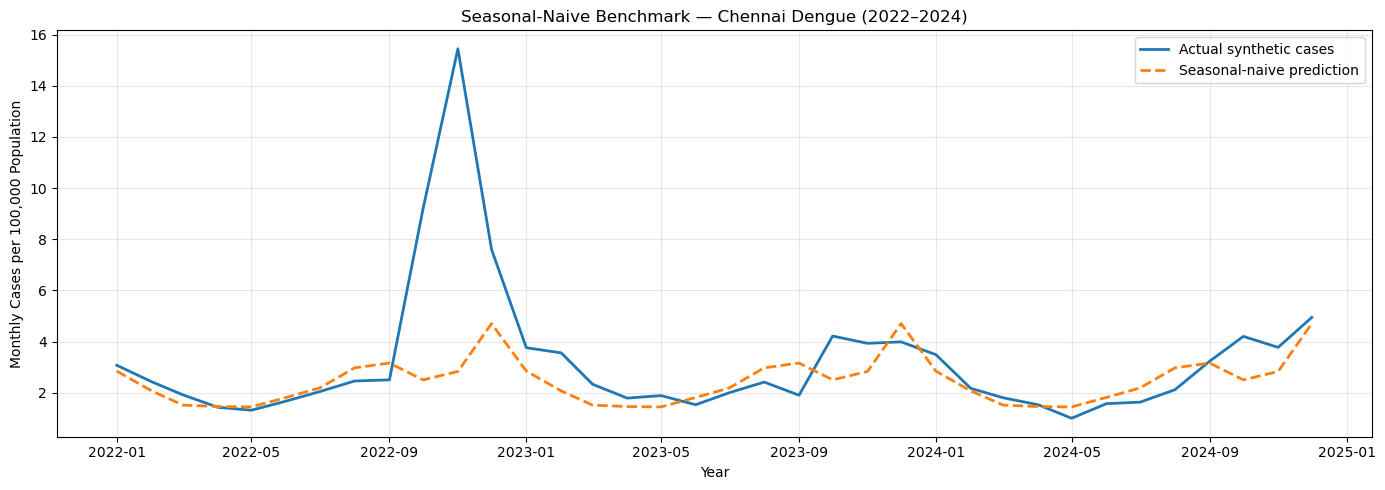

In [5]:

#  Visualise seasonal-naive benchmark
# Chennai dengue, 2022–2024

plot_data = test_naive[
    (test_naive["district_id"] == "chn") &
    (test_naive["disease_id"] == "dengue")
].sort_values("year_month")

plt.figure(figsize=(14, 5))

plt.plot(
    plot_data["year_month"],
    plot_data["cases_per_100k"],
    label="Actual synthetic cases",
    linewidth=2
)

plt.plot(
    plot_data["year_month"],
    plot_data["predicted_cases_per_100k"],
    label="Seasonal-naive prediction",
    linestyle="--",
    linewidth=2
)

plt.title(
    "Seasonal-Naive Benchmark — Chennai Dengue (2022–2024)"
)
plt.xlabel("Year")
plt.ylabel("Monthly Cases per 100,000 Population")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [6]:

# | Observation           | Interpretation                                       |
# |-----------------------|------------------------------------------------------|
# | January–August 2022   | Predictions generally follow the normal seasonal     |
# |                       | pattern.                                             |
# | October–November 2022 | The model substantially underpredicts the major      |
# |                       | outbreak.                                            |
# | Early 2023            | Predictions do not fully capture the post-outbreak   |
# |                       | decline.                                             |
# | Late 2023–2024        | The model captures some seasonal fluctuations but    |
# |                       | misses several peaks.                                |


In [ ]:

# Evaluate benchmark errors during outbreak months
# Rebuild seasonal thresholds from baseline training data (2015–2021)

thresholds = train.copy()

thresholds["calendar_month"] = (
    thresholds["year_month"].dt.month
)

thresholds = (
    thresholds.groupby(
        ["district_id", "disease_id", "calendar_month"],
        as_index=False
    )["cases"]
    .median()
    .rename(columns={"cases": "training_median_cases"})
)

# Match the 1.2 threshold factor verified in Notebook 01
thresholds["threshold_cases"] = (
    thresholds["training_median_cases"] * 1.2
)

# Join thresholds to evaluation data
outbreak_eval = evaluation.copy()

outbreak_eval["calendar_month"] = (
    outbreak_eval["year_month"].dt.month
)

outbreak_eval = outbreak_eval.merge(
    thresholds[
        ["district_id", "disease_id",
         "calendar_month", "threshold_cases"]
    ],
    on=["district_id", "disease_id", "calendar_month"],
    how="left",
    validate="many_to_one"
)

outbreak_eval["is_outbreak_month"] = (
    outbreak_eval["cases"] > outbreak_eval["threshold_cases"]
)

summary = (
    outbreak_eval.groupby(
        ["disease_id", "is_outbreak_month"]
    )
    .agg(
        observations=("absolute_error", "size"),
        MAE=("absolute_error", "mean"),
        MSE=("squared_error", "mean")
    )
    .reset_index()
)

summary["RMSE"] = np.sqrt(summary["MSE"])

summary = summary[
    ["disease_id", "is_outbreak_month",
     "observations", "MAE", "RMSE"]
]

print("=== SEASONAL-NAIVE PERFORMANCE BY OUTBREAK STATUS ===")
display(summary.round(3))

print("\nThreshold rows:", len(thresholds))
print(
    "Missing threshold matches:",
    outbreak_eval["threshold_cases"].isna().sum()
)


=== SEASONAL-NAIVE PERFORMANCE BY OUTBREAK STATUS ===


,disease_id,is_outbreak_month,observations,MAE,RMSE
0,dengue,False,129,0.488,0.651
1,dengue,True,51,2.651,4.356
2,malaria,False,133,0.215,0.286
3,malaria,True,47,0.759,1.144



Threshold rows: 120
Missing threshold matches: 0


In [10]:



output_dir = ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

prediction_path = output_dir / "seasonal_naive_predictions.csv"
metrics_path = output_dir / "seasonal_naive_metrics.csv"
threshold_path = output_dir / "recovery_thresholds.csv"

test_naive.to_csv(prediction_path, index=False)
metrics.to_csv(metrics_path, index=False)

# Save the thresholds calculated from training data
thresholds.to_csv(threshold_path, index=False)

print("=== SAVED FILES ===")

for path in [
    prediction_path,
    metrics_path,
    threshold_path
]:
    print(f"{path.name}: {path.exists()}")

print("\nPrediction rows:", len(test_naive))
print("Metrics rows:", len(metrics))
print("Threshold rows:", len(thresholds))


=== SAVED FILES ===
seasonal_naive_predictions.csv: True
seasonal_naive_metrics.csv: True
recovery_thresholds.csv: True

Prediction rows: 360
Metrics rows: 2
Threshold rows: 120
